# 02 – Cleaning and Splits
Leak-free, fixed train/validation/test splits shared by every model.

In [1]:
import sys, json, re
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.data import load_raw, LABELS, TEXT_COL, LABEL_COL, SEED, PROCESSED_DIR, RESULTS_DIR
from src.preprocess import clean_text
from src.plotting import set_style, save, SERIES, TEXT, TEXT_SECONDARY

set_style()
pd.set_option("display.max_colwidth", 140)
df = load_raw()
len(df)

47837

## 1. Check `clean_text()`
Applied to the corpus it should change almost nothing.

In [2]:
df["text"] = df[TEXT_COL].map(clean_text)
changed = df["text"] != df[TEXT_COL]
print(f"Tickets changed by clean_text(): {changed.sum()} of {len(df)} ({changed.mean():.2%})")
print("Changes are only stray '.'/',' characters and a few leftover contraction fragments (e.g. 'll').")
df.loc[changed, [TEXT_COL, "text"]].head(5)

Tickets changed by clean_text(): 406 of 47837 (0.85%)
Changes are only stray '.'/',' characters and a few leftover contraction fragments (e.g. 'll').


,Document,text
1646,"recurrent notification wireless vs wired automated ticket to be set up snow recurrent wireless vs ..., pc si validate",recurrent notification wireless vs wired automated ticket to be set up snow recurrent wireless vs pc si validate
3938,credential hello credentials enter cheers,credential hello credentials enter cheers
8787,hi lite hybrid cover lite lite honor lite grid red device exists needs installation also please two more tickets retrieval cleanup use...,hi lite hybrid cover lite lite honor lite grid red device exists needs installation also please two more tickets retrieval cleanup user ...
8966,hey has please log installation by supporters thanks administrator phone thursday hello received items po please advise please log tha...,hey has please log installation by supporters thanks administrator phone thursday hello received items po please advise please log thank...
9073,hi lite mobile subscription voice main please accessories device growth please log installation thanks administrator phone,hi lite mobile subscription voice main please accessories device growth please log installation thanks administrator phone


New, natural-language tickets after cleaning:

In [3]:
demo = [
    "Hi, I changed my password yesterday and now Outlook keeps rejecting my login!",
    "The Wi-Fi in meeting room 3B keeps dropping. Can someone check it?",
    "Please increase the size of my shared folder, it's full.",
    "We need a PO raised for 2 new monitors.",
]
pd.DataFrame({"original": demo, "cleaned": [clean_text(t) for t in demo]})

,original,cleaned
0,"Hi, I changed my password yesterday and now Outlook keeps rejecting my login!",hi changed password yesterday and now outlook keeps rejecting log
1,The Wi-Fi in meeting room 3B keeps dropping. Can someone check it?,the wireless meeting room keeps dropping can someone check it
2,"Please increase the size of my shared folder, it's full.",please increase the size of shared folder it full
3,We need a PO raised for 2 new monitors.,we need a po raised for new monitors


## 2. Near-duplicates
Templated tickets differing only by date are collapsed to one copy to prevent train/test leakage.

In [4]:
DATE_TOKENS = r"\b(monday|tuesday|wednesday|thursday|friday|saturday|sunday|january|february|march|april|may|june|july|august|september|october|november|december|pm|am|re|fw|sent)\b"
df["dedup_key"] = df["text"].str.replace(DATE_TOKENS, " ", regex=True).str.split().str.join(" ")

group_sizes = df.groupby("dedup_key").size()
dup_groups = group_sizes[group_sizes > 1]
print(f"Near-duplicate groups: {len(dup_groups)}, covering {dup_groups.sum()} tickets")
print(f"Extra copies that would be removed: {dup_groups.sum() - len(dup_groups)}")
dup_groups.sort_values(ascending=False).head(5).rename("copies").to_frame()

Near-duplicate groups: 386, covering 1232 tickets
Extra copies that would be removed: 846


,copies
dedup_key,
new purchase po purchase po dear purchased please log installation please take consideration mandatory receipts section order receive item ordered kind regards administrator,32
new starter bucharest hello va date administration officer,20
access request for a list or library library requesting library links library manage setting library note site site site provides central storage collaboration information ideas site tool collaboration tool communication meeting tool decision making site helps groups work teams social groups share information work together example site help coordinate calendars schedules discuss ideas review proposals share information keep touch other sites dynamic interactive members site contribute own ideas content well comment contribute other,16
new purchase po purchase po dear purchased please log installation please take consideration mandatory receipts section order receive item ordered how video kind regards administrator,16
new starter starter form ext,15


## 3. Conflicting labels
Near-identical tickets routed to different groups are dropped.

In [5]:
n_labels = df.groupby("dedup_key")[LABEL_COL].nunique()
conflict_keys = n_labels[n_labels > 1].index
conflicts = df[df.dedup_key.isin(conflict_keys)].sort_values("dedup_key")
print(f"Conflicting groups: {len(conflict_keys)}, tickets: {len(conflicts)}")
conflicts[["dedup_key", LABEL_COL]].head(10)

Conflicting groups: 13, tickets: 48


,dedup_key,Topic_group
24466,access request for a list or library library requesting library links library manage setting library please specify level require write ...,Hardware
24113,access request for a list or library library requesting library links library manage setting library please specify level require write ...,Storage
28470,access request for a site site requesting links site manage setting site note site,HR Support
28935,access request for a site site requesting links site manage setting site note site,Hardware
30110,access request for a site site requesting links site manage setting site note site,HR Support
30518,access request for a site site requesting links site manage setting site note site,Hardware
24950,access request for a site site requesting links site manage setting site note site,Hardware
30744,access request for a site site requesting links site manage setting site note site,HR Support
33000,access request for a site site requesting links site manage setting site note site,HR Support
31956,access request for a site site requesting links site manage setting site note site,Hardware


In [6]:
clean = (df[~df.dedup_key.isin(conflict_keys)]
           .drop_duplicates("dedup_key", keep="first")
           .loc[lambda d: d["text"].str.split().str.len() >= 2])
clean = clean.rename(columns={LABEL_COL: "label"})[["text", "label"]].reset_index(drop=True)

funnel = pd.Series({
    "Original tickets": len(df),
    "After removing conflicting labels": int((~df.dedup_key.isin(conflict_keys)).sum()),
    "After removing near-duplicates": len(clean),
})
funnel.to_frame("tickets")

,tickets
Original tickets,47837
After removing conflicting labels,47789
After removing near-duplicates,46978


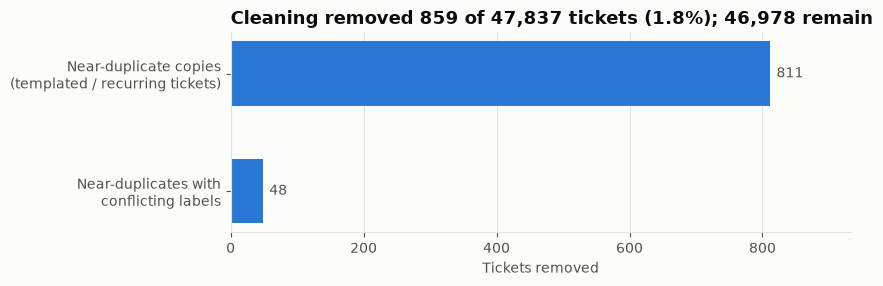

In [7]:
removed_by_reason = pd.Series({
    "Near-duplicate copies\n(templated / recurring tickets)": funnel.iloc[1] - funnel.iloc[2],
    "Near-duplicates with\nconflicting labels": funnel.iloc[0] - funnel.iloc[1],
})
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(removed_by_reason.index[::-1], removed_by_reason.values[::-1], color=SERIES, height=0.55)
for y, v in enumerate(removed_by_reason.values[::-1]):
    ax.text(v + 10, y, f"{v:,}", va="center", color=TEXT_SECONDARY, fontsize=10)
ax.set_xlim(0, removed_by_reason.max() * 1.15)
ax.set_xlabel("Tickets removed")
ax.grid(axis="y", visible=False)
ax.set_title(f"Cleaning removed {len(df) - len(clean):,} of {len(df):,} tickets ({(len(df) - len(clean)) / len(df):.1%}); {len(clean):,} remain")
save(fig, "06_cleaning_removed")
plt.show()

Class balance before vs. after cleaning:

In [8]:
before = df[LABEL_COL].value_counts(normalize=True).reindex(LABELS).mul(100).round(1)
after = clean["label"].value_counts(normalize=True).reindex(LABELS).mul(100).round(1)
removed = (df[LABEL_COL].value_counts() - clean["label"].value_counts()).reindex(LABELS)
pd.DataFrame({"% before": before, "% after": after, "tickets removed": removed})

,% before,% after,tickets removed
Hardware,28.5,28.7,148
HR Support,22.8,22.6,285
Access,14.9,15.0,67
Miscellaneous,14.8,14.9,67
Storage,5.8,5.8,39
Purchase,5.2,4.8,222
Internal Project,4.4,4.5,21
Administrative rights,3.7,3.7,10


## 4. Stratified 70 / 15 / 15 split
Train to learn, validation to tune and stop early, test used once at the end.

In [9]:
train, temp = train_test_split(clean, test_size=0.30, stratify=clean["label"], random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["label"], random_state=SEED)

assert not (set(train.text) & set(test.text)) and not (set(train.text) & set(val.text)) and not (set(val.text) & set(test.text))

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for name, part in [("train", train), ("val", val), ("test", test)]:
    part.reset_index(drop=True).to_csv(PROCESSED_DIR / f"{name}.csv", index=False)
    print(f"{name:5s} {len(part):6,d} rows -> data/processed/{name}.csv")

train 32,884 rows -> data/processed/train.csv
val    7,047 rows -> data/processed/val.csv
test   7,047 rows -> data/processed/test.csv


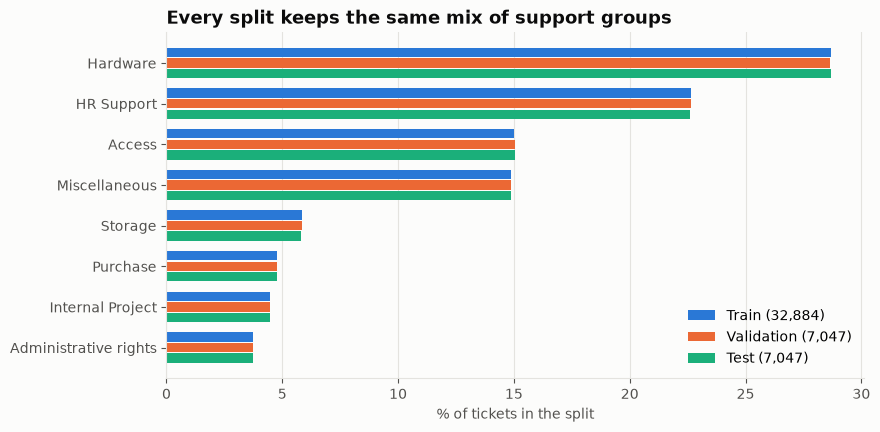

,Train,Validation,Test
label,,,
Hardware,28.7,28.7,28.7
HR Support,22.6,22.6,22.6
Access,15.0,15.0,15.0
Miscellaneous,14.9,14.9,14.9
Storage,5.8,5.8,5.8
Purchase,4.8,4.8,4.8
Internal Project,4.5,4.5,4.5
Administrative rights,3.7,3.7,3.7


In [10]:
shares = pd.DataFrame({n: p["label"].value_counts(normalize=True).reindex(LABELS) * 100
                       for n, p in [("Train", train), ("Validation", val), ("Test", test)]})
colors = {"Train": "#2a78d6", "Validation": "#eb6834", "Test": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(LABELS))
h = 0.26
for i, col in enumerate(shares.columns):
    ax.barh(y + (i - 1) * h, shares[col], height=h - 0.03, color=colors[col], label=f"{col} ({len([train, val, test][i]):,})")
ax.set_yticks(y, LABELS)
ax.invert_yaxis()
ax.set_xlabel("% of tickets in the split")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Every split keeps the same mix of support groups")
save(fig, "07_split_distribution")
plt.show()
shares.round(1)

In [11]:
summary = {
    "original_rows": len(df),
    "conflicting_groups_removed": int(len(conflict_keys)),
    "conflicting_tickets_removed": int(len(conflicts)),
    "near_duplicate_copies_removed": int(funnel.iloc[1] - funnel.iloc[2]),
    "final_rows": len(clean),
    "split_sizes": {"train": len(train), "val": len(val), "test": len(test)},
    "seed": SEED,
}
(RESULTS_DIR / "split_summary.json").write_text(json.dumps(summary, indent=2))
summary

{'original_rows': 47837,
 'conflicting_groups_removed': 13,
 'conflicting_tickets_removed': 48,
 'near_duplicate_copies_removed': 811,
 'final_rows': 46978,
 'split_sizes': {'train': 32884, 'val': 7047, 'test': 7047},
 'seed': 42}